# RAG in a browser tab: int8 embedding indexes and the size-recall trade-off

The VeriDex web app runs retrieval inside the browser: the page downloads an embedding model and a vector index, and no server ever sees the search. That only works if the download is small. This notebook measures what each way of shrinking the index costs in retrieval quality: float16, int8 with one scale per vector (the format the app ships), int4, binary codes, and PCA. It then checks the other half of the pipeline, the ONNX query encoder, in its fp32, fp16 and int8 exports.

Data: the [VeriDex RAG corpus](https://www.kaggle.com/datasets/swapnilshukla007/veridex-rag-corpus) dataset (1,234 structure-aware chunks, 157 questions). Run time: about 7 minutes on a 4-thread laptop CPU, most of it embedding the chunks. No GPU needed; internet is used to download `bge-small-en-v1.5` and its ONNX exports.

Links: [live app](https://swapnil007-curious.github.io/VeriDex/) · [GitHub repo](https://github.com/Swapnil007-Curious/VeriDex) · paper (link to be added)

Part 5 of the 5-part VeriDex series on building and checking a RAG system.

## Contents

1. Setup
2. The reference index
3. Seven ways to store the vectors
4. Size against agreement and recall
5. The file the browser downloads
6. The query encoder: ONNX fp32, fp16 and int8
7. What it means at app scale
8. What we found

## 1. Setup

`onnxruntime` is installed only if the image lacks it (the browser uses ONNX Runtime Web; the Python package runs the same model files).

In [1]:
import importlib.util
import subprocess
import sys


def ensure(package: str, module: str) -> None:
    """Install a pinned package only when the environment does not already provide the module."""
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)


ensure("sentence-transformers==6.2.0", "sentence_transformers")
ensure("onnxruntime==1.31.1", "onnxruntime")

In [2]:
import gzip
import json
import math
import os
import random
import struct
import time
import warnings
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()  # keep library notices out of the outputs

In [3]:
SEED = 42  # seeds Python, NumPy and PyTorch
EMBED_MODEL = "BAAI/bge-small-en-v1.5"  # 384-dimensional embeddings, the model the app runs
QUERY_INSTRUCTION = "Represent this sentence for searching relevant passages: "  # bge v1.5 query prefix
ONNX_REPO = "Xenova/bge-small-en-v1.5"  # ONNX exports used by Transformers.js
ONNX_REVISION = "ea104dacec62c0de699686887e3f920caeb4f3e3"  # the revision the app pins
ONNX_FILES = {"ONNX fp32": "onnx/model.onnx", "ONNX fp16": "onnx/model_fp16.onnx", "ONNX int8": "onnx/model_quantized.onnx"}
TOP_K = 5  # agreement and recall are measured on the top 5
K_RANK = 10  # nDCG@10
RESCORE_N = 50  # binary search keeps this many candidates for int8 rescoring
PCA_DIMS = [128, 64]  # reduced dimensions to try
APP_PASSAGES = 14_064  # passages in the five VeriDex app libraries (repository README)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
COLLECTION_LABELS = {"consumer_rules": "Consumer rules", "cs_ai": "CS / AI textbooks"}

# One Okabe-Ito colour per family of formats (distinguishable with the common forms of colour blindness),
# one marker per format inside a family, so no colour has to repeat across the ten formats
STYLE = {
    "float32": ("#0072B2", "o"), "float16": ("#0072B2", "s"),
    "int8, per-vector scale": ("#E69F00", "o"), "int8, global scale": ("#E69F00", "s"),
    "int4, per-vector scale": ("#009E73", "o"), "binary": ("#009E73", "s"), "binary + int8 rescore": ("#009E73", "^"),
    "PCA 128 + int8": ("#CC79A7", "o"), "PCA 64 + int8": ("#CC79A7", "s"), "first 128 dims + int8": ("#CC79A7", "^"),
}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})


def set_seed(seed: int = SEED) -> None:
    """Seed every random number generator the notebook touches."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def takeaway(text: str) -> None:
    """Show the one-line conclusion under a plot."""
    display(Markdown(f"> {text}"))


set_seed()
NOTEBOOK_START = time.time()
print(f"device: {DEVICE}, torch {torch.__version__}")

device: cpu, torch 2.15.0+cpu


## 2. The reference index

The reference is what a server would do: float32 `bge-small` embeddings of every chunk, a float32 query embedding from PyTorch, and exact cosine search. Every other variant is judged by how often it returns the same top 5 and by how much Recall@5 it loses against the gold passages.

In [4]:
def find_data_dir() -> Path:
    """Locate the veridex-rag-corpus dataset under /kaggle/input (or VERIDEX_DATA_DIR when run elsewhere)."""
    if os.environ.get("VERIDEX_DATA_DIR"):
        return Path(os.environ["VERIDEX_DATA_DIR"])
    for manifest in Path("/kaggle/input").glob("**/MANIFEST.json"):
        if json.loads(manifest.read_text(encoding="utf-8")).get("dataset") == "veridex-rag-corpus":
            return manifest.parent
    raise FileNotFoundError("Add the veridex-rag-corpus dataset to this notebook (Add Input).")


def read_jsonl(path: Path) -> list[dict]:
    """Read a JSON-lines file into a list of dicts."""
    with open(path, encoding="utf-8") as fh:
        return [json.loads(line) for line in fh if line.strip()]


DATA_DIR = find_data_dir()
WORK_DIR = Path(os.environ.get("VERIDEX_WORK_DIR", "/kaggle/working"))
WORK_DIR.mkdir(parents=True, exist_ok=True)

texts = {p.stem: p.read_text(encoding="utf-8") for p in (DATA_DIR / "text").glob("*.txt")}
nodes = {n["node_id"]: n for n in read_jsonl(DATA_DIR / "structure" / "nodes.jsonl")}
questions = read_jsonl(DATA_DIR / "questions" / "questions.jsonl")
chunks = {c: read_jsonl(DATA_DIR / "chunks" / c / "structural.jsonl") for c in COLLECTION_LABELS}
print({COLLECTION_LABELS[c]: len(v) for c, v in chunks.items()}, f"{len(questions)} questions")

{'Consumer rules': 111, 'CS / AI textbooks': 1123} 157 questions


In [5]:
from sentence_transformers import SentenceTransformer

st_model = SentenceTransformer(EMBED_MODEL, device=DEVICE)


def st_encode(texts: list, query: bool = False) -> np.ndarray:
    """Float32 L2-normalised embeddings from PyTorch (the server-side reference)."""
    inputs = [QUERY_INSTRUCTION + t for t in texts] if query else texts
    return st_model.encode(inputs, batch_size=32, normalize_embeddings=True, convert_to_numpy=True,
                           show_progress_bar=False).astype(np.float32)


t0 = time.time()
corpus = {c: st_encode([x["text"] for x in chunks[c]]) for c in COLLECTION_LABELS}
query_vecs = {q["uid"]: v for q, v in zip(questions, st_encode([q["question"] for q in questions], query=True))}
print(f"embedded {sum(len(v) for v in corpus.values())} chunks and {len(questions)} queries in {time.time() - t0:.0f} s")

embedded 1234 chunks and 157 queries in 267 s


The relevance rule is the one from notebooks 1 and 2: a chunk is relevant to a gold node when it holds part of that node's own text, or of a descendant or a non-chapter ancestor of it.

In [6]:
children = defaultdict(list)
for n in sorted(nodes.values(), key=lambda x: (x["doc_id"], x["order"])):
    if n["parent_id"] in nodes:
        children[n["parent_id"]].append(n["node_id"])


def own_spans(n: dict) -> list:
    """Character spans of the node's own non-blank text (outside its children)."""
    kids = sorted((nodes[c] for c in children[n["node_id"]]), key=lambda k: k["char_start"])
    raw, cursor = [], n["char_start"]
    for k in kids:
        raw.append((cursor, max(cursor, k["char_start"])))
        cursor = max(cursor, k["char_end"])
    raw.append((cursor, n["char_end"]))
    out = []
    for a, b in raw:
        seg = texts[n["doc_id"]][a:b]
        if seg.strip():
            lead = len(seg) - len(seg.lstrip())
            out.append((a + lead, a + lead + len(seg.strip())))
    return out


def matching(gold: str) -> set:
    """The gold node, its descendants and its non-chapter ancestors."""
    out, cur = {gold}, nodes[gold]["parent_id"]
    while cur in nodes:
        if nodes[cur]["level"] != "chapter":
            out.add(cur)
        cur = nodes[cur]["parent_id"]
    stack = list(children[gold])
    while stack:
        x = stack.pop()
        out.add(x)
        stack.extend(children[x])
    return out


spans_by_doc = defaultdict(list)
for n in nodes.values():
    if n["level"] != "chapter":
        spans_by_doc[n["doc_id"]] += [(a, b, n["node_id"]) for a, b in own_spans(n)]
for coll in COLLECTION_LABELS:
    for c in chunks[coll]:
        c["covered"] = {nid for a, b, nid in spans_by_doc[c["doc_id"]] if a < c["char_end"] and b > c["char_start"]}
gold_match = {q["uid"]: {g: matching(g) for g in q["gold_node_ids"]} for q in questions}


def recall_at(uid: str, coll: str, ranked: list, k: int = TOP_K) -> float:
    """Share of the question's gold nodes covered by the top-k chunks."""
    golds = gold_match[uid]
    hit = {g for i in ranked[:k] for g, m in golds.items() if chunks[coll][i]["covered"] & m}
    return len(hit) / len(golds)

## 3. Seven ways to store the vectors

Each variant stores the 384-dimensional chunk vectors differently and searches them with a float32 query, as the browser does:

- float32: 4 bytes per dimension, the reference;
- float16: 2 bytes per dimension;
- int8, one scale per vector: each vector is divided by its largest absolute value over 127 and rounded; 1 byte per dimension plus a 4-byte scale. This is the app's `vectors.bin`;
- int8, one global scale: the same, with one scale for the whole index;
- int4, one scale per vector: values from -7 to 7, two per byte;
- binary: one sign bit per dimension, searched by Hamming distance;
- binary, then int8 rescoring: Hamming search for 50 candidates, re-ranked with the int8 vectors (both stored);
- PCA to 128 or 64 dimensions, stored as int8 with one scale per vector, and plain truncation to the first 128 dimensions for comparison.

In [7]:
def quantize_rows(m: np.ndarray, levels: int) -> tuple:
    """Symmetric quantization with one float32 scale per row: m ~= scale * q, |q| <= levels."""
    peak = np.abs(m).max(axis=1)
    scale = np.where(peak > 0, peak / levels, 1.0).astype(np.float32)
    q = np.clip(np.rint(m / scale[:, None]), -levels, levels).astype(np.int8)
    return q, scale


def search(scores: np.ndarray, k: int) -> list:
    """Top-k indices, best first, ties broken by row order (as in the browser)."""
    return [int(i) for i in np.lexsort((np.arange(len(scores)), -scores))[:k]]


class Variant:
    """One storage format: builds from float32 vectors, reports its size, scores a float32 query."""

    def __init__(self, name: str, build, score, nbytes) -> None:
        self.name, self._build, self._score, self._nbytes = name, build, score, nbytes

    def fit(self, m: np.ndarray) -> "Variant":
        self.state = self._build(m)
        return self

    def scores(self, qv: np.ndarray) -> np.ndarray:
        return self._score(self.state, qv)

    def nbytes(self) -> int:
        return self._nbytes(self.state)

    def payload(self) -> bytes:
        """Raw bytes as they would be stored (for gzip sizes)."""
        return b"".join(np.ascontiguousarray(a).tobytes() for a in self.state.values() if isinstance(a, np.ndarray) and a.ndim > 0)


def pack_int4(q: np.ndarray) -> np.ndarray:
    """Two signed 4-bit values per byte."""
    u = (q.astype(np.int16) & 0x0F).astype(np.uint8)
    if u.shape[1] % 2:
        u = np.pad(u, ((0, 0), (0, 1)))
    return (u[:, 0::2] | (u[:, 1::2] << 4)).astype(np.uint8)


def unpack_int4(p: np.ndarray, dim: int) -> np.ndarray:
    lo, hi = (p & 0x0F).astype(np.int16), (p >> 4).astype(np.int16)
    out = np.empty((p.shape[0], p.shape[1] * 2), dtype=np.int16)
    out[:, 0::2], out[:, 1::2] = lo, hi
    out[out > 7] -= 16
    return out[:, :dim].astype(np.float32)


def hamming_scores(bits: np.ndarray, qv: np.ndarray) -> np.ndarray:
    """Negative Hamming distance between packed sign bits of the rows and of the query."""
    qbits = np.packbits(qv > 0)
    return -np.unpackbits(bits ^ qbits, axis=1).sum(axis=1).astype(np.float32)


def make_variants(m_all: np.ndarray) -> list:
    """All storage variants; PCA is fitted on the given corpus vectors."""
    dim = m_all.shape[1]

    def build_int4(m):
        q4, sc = quantize_rows(m, 7)
        return {"p": pack_int4(q4), "s": sc, "dim": dim}

    variants = [
        Variant("float32", lambda m: {"m": m.astype(np.float32)}, lambda s, q: s["m"] @ q, lambda s: s["m"].nbytes),
        Variant("float16", lambda m: {"m": m.astype(np.float16)}, lambda s, q: s["m"].astype(np.float32) @ q, lambda s: s["m"].nbytes),
        Variant("int8, per-vector scale", lambda m: dict(zip(("q", "s"), quantize_rows(m, 127))),
                lambda s, q: (s["q"].astype(np.float32) @ q) * s["s"], lambda s: s["q"].nbytes + s["s"].nbytes),
        Variant("int8, global scale",
                lambda m: {"q": np.clip(np.rint(m / (np.abs(m).max() / 127)), -127, 127).astype(np.int8), "g": np.float32(np.abs(m).max() / 127)},
                lambda s, q: (s["q"].astype(np.float32) @ q) * s["g"], lambda s: s["q"].nbytes + 4),
        Variant("int4, per-vector scale", build_int4, lambda s, q: (unpack_int4(s["p"], s["dim"]) @ q) * s["s"],
                lambda s: s["p"].nbytes + s["s"].nbytes),
        Variant("binary", lambda m: {"b": np.packbits(m > 0, axis=1)}, lambda s, q: hamming_scores(s["b"], q), lambda s: s["b"].nbytes),
    ]

    def build_rescore(m):
        q8, sc = quantize_rows(m, 127)
        return {"b": np.packbits(m > 0, axis=1), "q": q8, "s": sc}

    def score_rescore(s, q):
        ham = hamming_scores(s["b"], q)
        cand = search(ham, RESCORE_N)
        out = np.full(len(ham), -np.inf, dtype=np.float32)
        out[cand] = (s["q"][cand].astype(np.float32) @ q) * s["s"][cand]
        return out

    variants.append(Variant("binary + int8 rescore", build_rescore, score_rescore,
                            lambda s: s["b"].nbytes + s["q"].nbytes + s["s"].nbytes))
    mean = m_all.mean(axis=0)
    _, _, vt = np.linalg.svd(m_all - mean, full_matrices=False)
    for d in PCA_DIMS:
        proj = vt[:d].T.astype(np.float32)

        def build_pca(m, proj=proj):
            return dict(zip(("q", "s"), quantize_rows((m - mean) @ proj, 127)))

        def score_pca(s, q, proj=proj):
            # reconstructed row . q = mean . q + ((row - mean) @ proj) . (q @ proj); mean . q is the same for every row
            return (s["q"].astype(np.float32) @ (q @ proj)) * s["s"]

        variants.append(Variant(f"PCA {d} + int8", build_pca, score_pca, lambda s, d=d: s["q"].nbytes + s["s"].nbytes + (d + 1) * dim * 4))
    variants.append(Variant("first 128 dims + int8", lambda m: dict(zip(("q", "s"), quantize_rows(m[:, :128], 127))),
                            lambda s, q: (s["q"].astype(np.float32) @ q[:128]) * s["s"], lambda s: s["q"].nbytes + s["s"].nbytes))
    return variants

PCA is fitted on all chunk vectors of both collections, which is what an app would do at build time. Its projection matrix and mean vector travel with the index, so their size counts.

In [8]:
def evaluate(variant_name: str, query_vectors: dict | None = None) -> dict:
    """Agreement with the float32 reference and Recall@5 for one variant, over both collections."""
    qv_all = query_vectors or query_vecs
    same, overlap, recalls, size, gz, ms = [], [], [], 0, 0, []
    for coll in COLLECTION_LABELS:
        v = next(x for x in variants[coll] if x.name == variant_name)
        ref = variants[coll][0]
        size += v.nbytes()
        gz += len(gzip.compress(v.payload(), compresslevel=9, mtime=0))
        for q in (q for q in questions if q["collection"] == coll):
            t0 = time.perf_counter()
            top = search(v.scores(qv_all[q["uid"]]), TOP_K)
            ms.append(1000 * (time.perf_counter() - t0))
            ref_top = search(ref.scores(query_vecs[q["uid"]]), TOP_K)
            same.append(top == ref_top)
            overlap.append(len(set(top) & set(ref_top)) / TOP_K)
            if q["answerable"]:
                recalls.append(recall_at(q["uid"], coll, top))
    return {"variant": variant_name, "bytes": size, "gzip bytes": gz, "bytes per vector": size / sum(len(c) for c in chunks.values()),
            "identical top-5": np.mean(same), "top-5 overlap": np.mean(overlap), f"Recall@{TOP_K}": np.mean(recalls),
            "search ms": np.median(ms)}


all_vecs = np.vstack([corpus[c] for c in COLLECTION_LABELS])
variants = {c: [v.fit(corpus[c]) for v in make_variants(all_vecs)] for c in COLLECTION_LABELS}
VARIANT_NAMES = [v.name for v in variants["cs_ai"]]
res = pd.DataFrame([evaluate(name) for name in VARIANT_NAMES]).set_index("variant")
res["size vs float32"] = res["bytes"] / res.loc["float32", "bytes"]
res.style.format({"bytes": "{:,.0f}", "gzip bytes": "{:,.0f}", "bytes per vector": "{:.0f}", "identical top-5": "{:.1%}",
                  "top-5 overlap": "{:.1%}", f"Recall@{TOP_K}": "{:.3f}", "search ms": "{:.2f}", "size vs float32": "{:.3f}"})

,bytes,gzip bytes,bytes per vector,identical top-5,top-5 overlap,Recall@5,search ms,size vs float32
variant,,,,,,,,
float32,"1,895,424","1,758,813",1536,100.0%,100.0%,0.844,0.14,1.000
float16,"947,712","875,350",768,97.5%,99.9%,0.844,2.49,0.500
"int8, per-vector scale","478,792","370,973",388,70.7%,97.6%,0.844,1.21,0.253
"int8, global scale","473,864","348,386",384,70.7%,96.9%,0.844,1.17,0.250
"int4, per-vector scale","241,864","133,191",196,3.8%,73.1%,0.797,7.57,0.128
binary,"59,232","57,534",48,0.0%,52.2%,0.783,0.69,0.031
binary + int8 rescore,"538,024","429,662",436,62.4%,93.4%,0.854,0.80,0.284
PCA 128 + int8,"559,176","133,827",453,5.1%,75.8%,0.792,0.23,0.295
PCA 64 + int8,"283,592","73,099",230,1.3%,60.5%,0.684,0.15,0.150


Search time is NumPy on this session's CPU over about 1,100 vectors, so read it only as a relative cost; the browser runs a plain JavaScript loop.

## 4. Size against agreement and recall

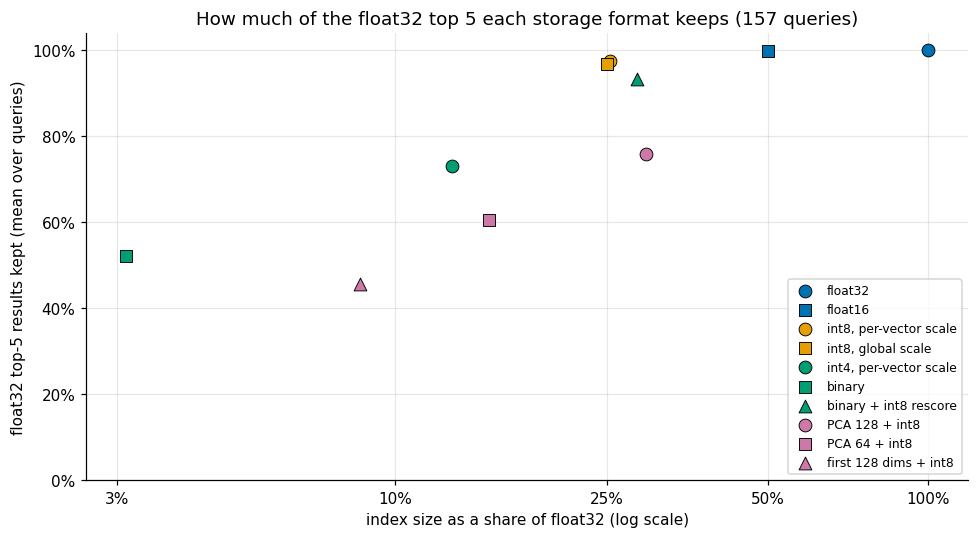

> int8 with one scale per vector keeps 97.6% of the float32 top 5 at 25% of the size (71% of queries get exactly the same ranked list); binary codes alone keep 52%.

In [9]:
from matplotlib.ticker import FixedLocator, NullLocator, PercentFormatter


def plot_size_tradeoff(ax, big: bool = False) -> None:
    """Index size against the share of the float32 top 5 that each format keeps, one marker per format."""
    for name, r in res.iterrows():
        colour, marker = STYLE[name]
        ax.scatter(r["size vs float32"], r["top-5 overlap"], s=180 if big else 70, color=colour, marker=marker,
                   edgecolor="black", linewidth=0.6, zorder=3, label=name)
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(FixedLocator([0.03, 0.1, 0.25, 0.5, 1.0]))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_xlabel("index size as a share of float32 (log scale)")
    ax.set_ylabel("float32 top-5 results kept (mean over queries)")
    ax.set_ylim(0, 1.04)
    ax.legend(fontsize=12 if big else 8, loc="lower right")


fig, ax = plt.subplots(figsize=(9, 5))
plot_size_tradeoff(ax)
ax.set_title(f"How much of the float32 top 5 each storage format keeps ({len(questions)} queries)")
plt.tight_layout()
plt.show()
r8 = res.loc["int8, per-vector scale"]
takeaway(f"int8 with one scale per vector keeps {r8['top-5 overlap']:.1%} of the float32 top 5 at {r8['size vs float32']:.0%} of the size "
         f"({r8['identical top-5']:.0%} of queries get exactly the same ranked list); binary codes alone keep {res.loc['binary', 'top-5 overlap']:.0%}.")

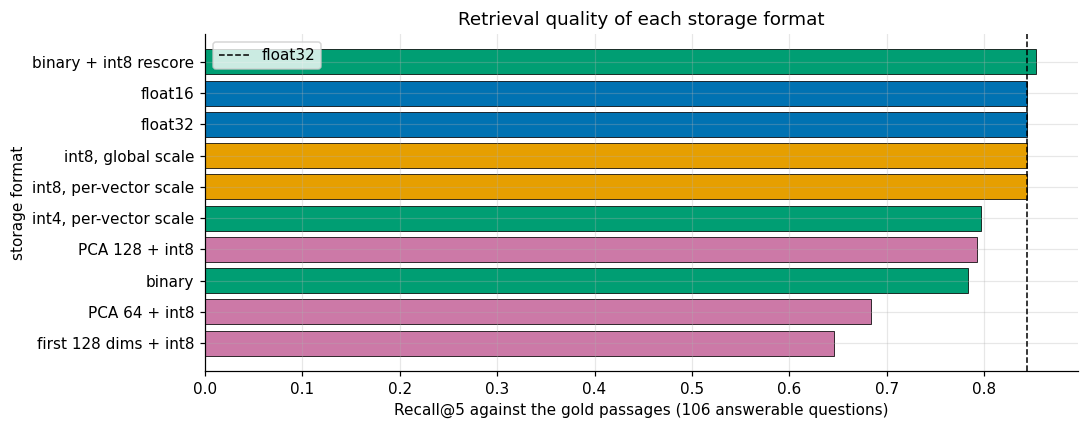

> Against the gold passages, int8 per-vector changes Recall@5 by +0.000, PCA to 64 dimensions by -0.160 and truncation to the first 128 dimensions by -0.198.

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
order = res.sort_values(f"Recall@{TOP_K}").index
ax.barh(order, res.loc[order, f"Recall@{TOP_K}"], color=[STYLE[n][0] for n in order], edgecolor="black", linewidth=0.5)
ax.axvline(res.loc["float32", f"Recall@{TOP_K}"], color="black", ls="--", lw=1, label="float32")
ax.set_xlabel(f"Recall@{TOP_K} against the gold passages (106 answerable questions)")
ax.set_ylabel("storage format")
ax.set_title("Retrieval quality of each storage format")
ax.legend()
plt.tight_layout()
plt.show()
change = (res[f"Recall@{TOP_K}"] - res.loc["float32", f"Recall@{TOP_K}"]).round(3) + 0.0  # + 0.0 turns -0.0 into 0.0
takeaway(f"Against the gold passages, int8 per-vector changes Recall@5 by {change['int8, per-vector scale']:+.3f}, "
         f"PCA to 64 dimensions by {change['PCA 64 + int8']:+.3f} and truncation to the first 128 dimensions by {change['first 128 dims + int8']:+.3f}.")

## 5. The file the browser downloads

The app's `vectors.bin` is a 16-byte header (magic `RAGV`, a version byte, 3 padding bytes, the dimension and the count as little-endian uint32), then one float32 scale per vector, then the int8 values row by row. Writing it and reading it back checks that the format round-trips exactly.

In [11]:
HEADER = struct.Struct("<4sB3xII")  # magic, version, padding, dim, count


def encode_vectors(q: np.ndarray, scale: np.ndarray) -> bytes:
    n, dim = q.shape
    return HEADER.pack(b"RAGV", 1, dim, n) + scale.astype("<f4").tobytes() + q.astype(np.int8).tobytes()


def decode_vectors(blob: bytes) -> tuple:
    magic, version, dim, n = HEADER.unpack_from(blob, 0)
    assert magic == b"RAGV" and version == 1, "not a vectors.bin file"
    scale = np.frombuffer(blob, dtype="<f4", count=n, offset=HEADER.size)
    q = np.frombuffer(blob, dtype=np.int8, count=n * dim, offset=HEADER.size + 4 * n).reshape(n, dim)
    return q, scale


q8, sc = quantize_rows(corpus["cs_ai"], 127)
blob = encode_vectors(q8, sc)
(WORK_DIR / "vectors.bin").write_bytes(blob)
q_back, s_back = decode_vectors((WORK_DIR / "vectors.bin").read_bytes())
print(f"header: {blob[:16].hex(' ')}")
print(f"{len(blob):,} bytes for {len(q8)} vectors ({len(blob) / len(q8):.0f} bytes each); gzip: {len(gzip.compress(blob, 9, mtime=0)):,} bytes")
print("round trip exact:", np.array_equal(q_back, q8) and np.array_equal(s_back, sc))
err = np.linalg.norm(q8.astype(np.float32) * sc[:, None] - corpus["cs_ai"], axis=1)
print(f"reconstruction error |x - scale*q|: median {np.median(err):.4f}, max {err.max():.4f} (vectors have norm 1)")

header: 52 41 47 56 01 00 00 00 80 01 00 00 63 04 00 00
435,740 bytes for 1123 vectors (388 bytes each); gzip: 337,079 bytes
round trip exact: True
reconstruction error |x - scale*q|: median 0.0157, max 0.0206 (vectors have norm 1)


## 6. The query encoder: ONNX fp32, fp16 and int8

The index is only half of in-browser retrieval: the browser also embeds the query, with an ONNX export of the same model. Transformers.js offers fp32, fp16 and an int8 "quantized" export of `bge-small`. The int8 model is half the download of fp16, so it is tempting. The cell below runs all three with ONNX Runtime and compares their query vectors with the PyTorch reference, searching the same int8 index.

In [12]:
import onnxruntime as ort
from huggingface_hub import hf_hub_download
from transformers import AutoTokenizer

onnx_tok = AutoTokenizer.from_pretrained(EMBED_MODEL)


def onnx_encoder(filename: str):
    """An ONNX Runtime session for one export, returning a function texts -> normalised CLS embeddings."""
    path = hf_hub_download(ONNX_REPO, filename, revision=ONNX_REVISION)
    sess = ort.InferenceSession(path, providers=["CPUExecutionProvider"])
    names = {i.name for i in sess.get_inputs()}

    def run(texts: list) -> np.ndarray:
        enc = onnx_tok([QUERY_INSTRUCTION + t for t in texts], padding=True, truncation=True, max_length=512, return_tensors="np")
        feed = {k: enc[k].astype(np.int64) for k in ("input_ids", "attention_mask", "token_type_ids") if k in names}
        cls = sess.run(None, feed)[0][:, 0].astype(np.float32)  # bge uses the [CLS] vector
        return cls / np.linalg.norm(cls, axis=1, keepdims=True)

    return run, os.path.getsize(path)


rows, onnx_query_vecs = [], {}
for label, filename in ONNX_FILES.items():
    run, size = onnx_encoder(filename)
    vecs = np.vstack([run([q["question"] for q in questions[i:i + 16]]) for i in range(0, len(questions), 16)])
    onnx_query_vecs[label] = {q["uid"]: v for q, v in zip(questions, vecs)}
    cos = np.array([float(onnx_query_vecs[label][q["uid"]] @ query_vecs[q["uid"]]) for q in questions])
    r = evaluate("int8, per-vector scale", onnx_query_vecs[label])
    rows.append({"query encoder": label, "model MB": size / 1e6, "cosine to PyTorch (min)": cos.min(),
                 "cosine to PyTorch (mean)": cos.mean(), "identical top-5": r["identical top-5"],
                 "top-5 overlap": r["top-5 overlap"], f"Recall@{TOP_K}": r[f"Recall@{TOP_K}"]})
enc_res = pd.DataFrame(rows).set_index("query encoder")
enc_res.style.format({"model MB": "{:.1f}", "cosine to PyTorch (min)": "{:.4f}", "cosine to PyTorch (mean)": "{:.4f}",
                      "identical top-5": "{:.1%}", "top-5 overlap": "{:.1%}", f"Recall@{TOP_K}": "{:.3f}"})

,model MB,cosine to PyTorch (min),cosine to PyTorch (mean),identical top-5,top-5 overlap,Recall@5
query encoder,,,,,,
ONNX fp32,133.1,1.0000,1.0000,70.7%,97.6%,0.844
ONNX fp16,66.7,1.0000,1.0000,70.1%,97.6%,0.844
ONNX int8,34.0,0.9947,0.9964,45.9%,93.1%,0.835


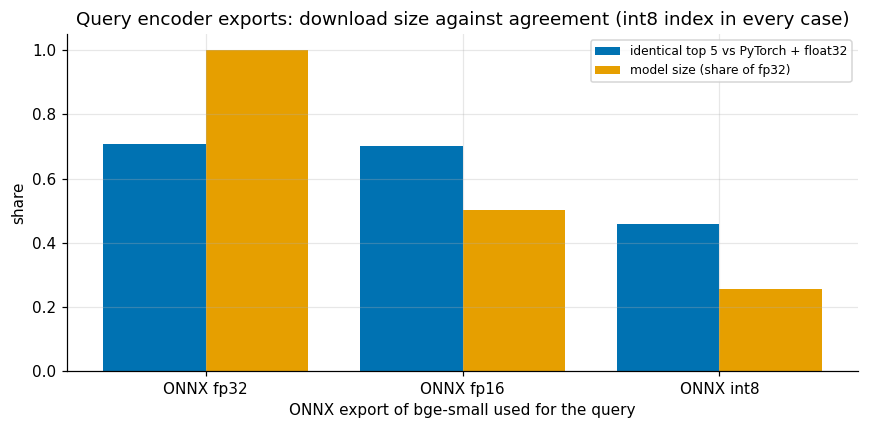

> The fp16 export keeps the top 5 for 70% of queries and the int8 export for 46%, against 71% for the int8 index with the PyTorch query: quantizing the encoder moves results more than quantizing the index.

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(enc_res))
ax.bar(x - 0.2, enc_res["identical top-5"], width=0.4, color="#0072B2", label="identical top 5 vs PyTorch + float32")
ax.bar(x + 0.2, enc_res["model MB"] / enc_res["model MB"].max(), width=0.4, color="#E69F00", label="model size (share of fp32)")
ax.set_xticks(x)
ax.set_xticklabels(enc_res.index)
ax.set_ylim(0, 1.05)
ax.set_xlabel("ONNX export of bge-small used for the query")
ax.set_ylabel("share")
ax.set_title("Query encoder exports: download size against agreement (int8 index in every case)")
ax.legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()
encoder_hurts_more = enc_res.loc["ONNX int8", "identical top-5"] < res.loc["int8, per-vector scale", "identical top-5"]
takeaway(f"The fp16 export keeps the top 5 for {enc_res.loc['ONNX fp16', 'identical top-5']:.0%} of queries and the int8 export for "
         f"{enc_res.loc['ONNX int8', 'identical top-5']:.0%}, against {res.loc['int8, per-vector scale', 'identical top-5']:.0%} for the int8 index with the PyTorch query: "
         + ("quantizing the encoder moves results more than quantizing the index." if encoder_hurts_more else "the int8 encoder costs no more than the int8 index."))

## 7. What it means at app scale

The five libraries of the VeriDex app hold 14,064 passages. The table projects the vector download for each format from the bytes per vector measured above, before HTTP compression.

In [14]:
proj = pd.DataFrame({"MB for 14,064 passages": res["bytes per vector"] * APP_PASSAGES / 1e6,
                     "identical top-5": res["identical top-5"], f"Recall@{TOP_K}": res[f"Recall@{TOP_K}"]})
proj.style.format({"MB for 14,064 passages": "{:.2f}", "identical top-5": "{:.0%}", f"Recall@{TOP_K}": "{:.3f}"})

,"MB for 14,064 passages",identical top-5,Recall@5
variant,,,
float32,21.60,100%,0.844
float16,10.80,97%,0.844
"int8, per-vector scale",5.46,71%,0.844
"int8, global scale",5.40,71%,0.844
"int4, per-vector scale",2.76,4%,0.797
binary,0.68,0%,0.783
binary + int8 rescore,6.13,62%,0.854
PCA 128 + int8,6.37,5%,0.792
PCA 64 + int8,3.23,1%,0.684


In [15]:
# Cover image for the Kaggle listing: the size trade-off at 1280 x 720 pixels
fig, ax = plt.subplots(figsize=(12.8, 7.2), dpi=100)
plot_size_tradeoff(ax, big=True)
ax.set_title("Shrinking a RAG index for the browser: size against top-5 results kept", fontsize=19)
ax.xaxis.label.set_fontsize(15)
ax.yaxis.label.set_fontsize(15)
ax.tick_params(labelsize=13)
fig.tight_layout()
fig.savefig(WORK_DIR / "cover.png", dpi=100)
plt.close(fig)
print(f"notebook run time so far: {(time.time() - NOTEBOOK_START) / 60:.1f} min")

notebook run time so far: 5.0 min


## 8. What we found

In [16]:
findings = [
    f"Storing `bge-small` vectors as int8 with one scale per vector cut the index to {r8['size vs float32']:.0%} of float32 and kept the exact float32 top 5 for "
    f"{r8['identical top-5']:.0%} of 157 queries. On average {r8['top-5 overlap']:.1%} of the float32 top 5 stayed in the int8 top 5, "
    + (f"and Recall@5 stayed at {r8[f'Recall@{TOP_K}']:.3f}." if round(r8[f'Recall@{TOP_K}'], 3) == round(res.loc['float32', f'Recall@{TOP_K}'], 3)
       else f"and Recall@5 went from {res.loc['float32', f'Recall@{TOP_K}']:.3f} to {r8[f'Recall@{TOP_K}']:.3f}."),
    f"float16 kept the top 5 for {res.loc['float16', 'identical top-5']:.0%} of queries, int4 for {res.loc['int4, per-vector scale', 'identical top-5']:.0%}, "
    f"and binary codes for {res.loc['binary', 'identical top-5']:.0%}, rising to {res.loc['binary + int8 rescore', 'identical top-5']:.0%} when the top {RESCORE_N} are rescored with int8.",
    f"PCA to 128 dimensions gave Recall@5 {res.loc['PCA 128 + int8', f'Recall@{TOP_K}']:.3f}, PCA to 64 gave {res.loc['PCA 64 + int8', f'Recall@{TOP_K}']:.3f}, "
    f"and keeping the first 128 of the 384 dimensions gave {res.loc['first 128 dims + int8', f'Recall@{TOP_K}']:.3f}; "
    + ("truncation lost the most, as expected for a model that was not trained to put its information in the first dimensions."
       if res.loc['first 128 dims + int8', f'Recall@{TOP_K}'] < res.loc[['PCA 128 + int8', 'PCA 64 + int8'], f'Recall@{TOP_K}'].min()
       else "on this small corpus, truncation did not lose more than PCA."),
    f"For the query encoder, the int8 ONNX export ({enc_res.loc['ONNX int8', 'model MB']:.0f} MB) kept the top 5 for "
    f"{enc_res.loc['ONNX int8', 'identical top-5']:.0%} of queries against {enc_res.loc['ONNX fp16', 'identical top-5']:.0%} for fp16 "
    f"({enc_res.loc['ONNX fp16', 'model MB']:.0f} MB); the VeriDex app ships the fp16 encoder with an int8 index.",
]
display(Markdown("\n\n".join(findings)))

Storing `bge-small` vectors as int8 with one scale per vector cut the index to 25% of float32 and kept the exact float32 top 5 for 71% of 157 queries. On average 97.6% of the float32 top 5 stayed in the int8 top 5, and Recall@5 stayed at 0.844.

float16 kept the top 5 for 97% of queries, int4 for 4%, and binary codes for 0%, rising to 62% when the top 50 are rescored with int8.

PCA to 128 dimensions gave Recall@5 0.792, PCA to 64 gave 0.684, and keeping the first 128 of the 384 dimensions gave 0.646; truncation lost the most, as expected for a model that was not trained to put its information in the first dimensions.

For the query encoder, the int8 ONNX export (34 MB) kept the top 5 for 46% of queries against 70% for fp16 (67 MB); the VeriDex app ships the fp16 encoder with an int8 index.

### Limitations

The corpus is small (1,234 chunks), so a 5-result window covers a large share of each collection and agreement rates may be higher than on a million-vector index, where near-ties are more common. "Identical top 5" counts order changes as disagreements, which is strict; overlap is reported alongside it. Search times are NumPy timings, which a browser's JavaScript loop will not match exactly. The int8 ONNX export is the one Transformers.js publishes; a quantization calibrated on in-domain text could behave better.

### Ideas to try

- Try product quantization (for example with `faiss`) for a finer size-recall curve.
- Fine-tune a Matryoshka embedding model and repeat the truncation test.
- Measure int8 agreement as the corpus grows by adding the `fixed_512` chunks.
- Quantize the encoder yourself with ONNX Runtime's dynamic quantization, excluding the embedding and last layers, and compare with the published int8 export.

### The VeriDex series

1. [Chunking legal text for RAG: structure-aware vs fixed vs semantic chunks](https://www.kaggle.com/code/swapnilshukla007/chunking-legal-text-for-rag)
2. [BM25, dense, RRF fusion and cross-encoder reranking: a retrieval ablation you can rerun](https://www.kaggle.com/code/swapnilshukla007/bm25-dense-rrf-and-reranking-rag-ablation)
3. [Catching unsupported sentences: NLI faithfulness checks for RAG answers](https://www.kaggle.com/code/swapnilshukla007/nli-faithfulness-checks-for-rag-answers)
4. [Teaching a RAG system to abstain: thresholds, coverage and selective accuracy](https://www.kaggle.com/code/swapnilshukla007/teaching-a-rag-system-to-abstain)
5. RAG in a browser tab (this notebook)

If you spot a mistake or get different numbers, please say so in the comments; an upvote helps other people find the notebook.